<style>
@media print {

    @page {
        size: A4 portrait;
        margin: 10mm;
    }

    /* Evitar que el contenedor del notebook recorte las salidas */
    body,
    main,
    article,
    .jp-Notebook,
    .jp-NotebookPanel-notebook,
    .notebook,
    .container {
        max-width: 100% !important;
        width: 100% !important;
        overflow: visible !important;
    }

    /* Contenedores de salida de Jupyter / VS Code */
    .jp-OutputArea,
    .jp-OutputArea-child,
    .jp-OutputArea-output,
    .jp-RenderedHTMLCommon,
    .output,
    .output_area,
    .output_subarea,
    .cell-output,
    div[data-mime-type="text/html"] {
        max-width: 100% !important;
        width: 100% !important;
        overflow: visible !important;
        overflow-x: visible !important;
    }

    /* TABLAS */
    table,
    table.dataframe {
        width: 100% !important;
        max-width: 100% !important;
        table-layout: fixed !important;
        border-collapse: collapse !important;

        /* tamaño todavía legible */
        font-size: 9pt !important;
    }

    table th,
    table td,
    table.dataframe th,
    table.dataframe td {
        padding: 3px 4px !important;

        /* ESTA ES LA PARTE CLAVE */
        white-space: normal !important;
        overflow-wrap: anywhere !important;
        word-break: break-word !important;

        text-align: center !important;
    }

    /* Gráficas e imágenes */
    img,
    svg,
    canvas {
        max-width: 100% !important;
        height: auto !important;
    }
}
</style>


<h1 style="text-align: center;">Tutorial: PCA y Sistemas de Recomendación</h1>

## Introducción
Los sistemas de recomendación son herramientas utilizadas para sugerir productos, contenidos o servicios a los usuarios de acuerdo con sus preferencias e interacciones previas. Actualmente se utilizan en distintas plataformas digitales para recomendar películas, música, productos, libros y otros contenidos de interés.

En este tutorial se desarrollará un sistema de recomendación de libros utilizando la base de datos Goodbooks 10k, obtenida de GitHub, la cual contiene información sobre usuarios, libros y las calificaciones asignadas por los usuarios en la plataforma Goodreads. A partir de estas calificaciones se construirá una matriz usuario-libro, donde cada fila representará a un usuario, cada columna a un libro y cada valor corresponderá a la calificación otorgada.

Debido a que cada usuario únicamente ha calificado una parte de los libros disponibles, la matriz contendrá una gran cantidad de valores faltantes. Para estimar estas calificaciones desconocidas se aplicará una estrategia de matrix completion, con el objetivo de reconstruir parcialmente la matriz y generar predicciones sobre qué libros podrían resultar de interés para cada usuario.

Durante el proceso se realizará el preprocesamiento de los datos, se ocultará una parte de las calificaciones conocidas para evaluar la capacidad de reconstrucción del sistema, se centrarán las calificaciones de acuerdo con el comportamiento de cada usuario y finalmente se generarán recomendaciones de libros que el usuario no haya calificado previamente.

El objetivo de este tutorial es mostrar de manera clara y reproducible cómo construir y evaluar un sistema de recomendación, explicando tanto el procedimiento utilizado como la interpretación de los resultados obtenidos.

## Paso 1. Importación de librerías y bases de datos

Para comenzar, se importarán las librerías necesarias para trabajar con los datos. Se utilizará pandas para cargar y manipular las bases de datos, NumPy para operaciones numéricas y posteriormente otras librerías para realizar visualizaciones, evaluar el sistema y aplicar el proceso de completado matricial.

Después, se cargarán cuatro bases de datos de Goodbooks 10k:
*   La base ratings.csv contiene las calificaciones realizadas por los usuarios.
*   La base books.csv contiene la información general de los libros.
*   Las bases book_tags.csv y tags.csv permitirán relacionar los libros con diferentes etiquetas que podrán utilizarse posteriormente para complementar las recomendaciones.

El objetivo de este primer paso es comprobar que los archivos se cargaron correctamente y observar de manera general la estructura de cada base de datos.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Cargar bases de datos
ratings = pd.read_csv("/ratings.csv")
books = pd.read_csv("/books.csv")
book_tags = pd.read_csv("/book_tags.csv")
tags = pd.read_csv("/tags.csv")

# Mostrar las primeras filas de cada base
print("RATINGS")
display(ratings.head())

print("\nBOOKS")
display(books.head())

print("\nBOOK TAGS")
display(book_tags.head())

print("\nTAGS")
display(tags.head())

RATINGS


,user_id,book_id,rating
0,1,258,5
1,2,4081,4
2,2,260,5
3,2,9296,5
4,2,2318,3



BOOKS


,book_id,goodreads_book_id,best_book_id,work_id,books_count,isbn,isbn13,authors,original_publication_year,original_title,...,ratings_count,work_ratings_count,work_text_reviews_count,ratings_1,ratings_2,ratings_3,ratings_4,ratings_5,image_url,small_image_url
0,1,2767052,2767052,2792775,272,439023483,9.780439e+12,Suzanne Collins,2008.0,The Hunger Games,...,4780653,4942365,155254,66715,127936,560092,1481305,2706317,https://images.gr-assets.com/books/1447303603m...,https://images.gr-assets.com/books/1447303603s...
1,2,3,3,4640799,491,439554934,9.780440e+12,"J.K. Rowling, Mary GrandPré",1997.0,Harry Potter and the Philosopher's Stone,...,4602479,4800065,75867,75504,101676,455024,1156318,3011543,https://images.gr-assets.com/books/1474154022m...,https://images.gr-assets.com/books/1474154022s...
2,3,41865,41865,3212258,226,316015849,9.780316e+12,Stephenie Meyer,2005.0,Twilight,...,3866839,3916824,95009,456191,436802,793319,875073,1355439,https://images.gr-assets.com/books/1361039443m...,https://images.gr-assets.com/books/1361039443s...
3,4,2657,2657,3275794,487,61120081,9.780061e+12,Harper Lee,1960.0,To Kill a Mockingbird,...,3198671,3340896,72586,60427,117415,446835,1001952,1714267,https://images.gr-assets.com/books/1361975680m...,https://images.gr-assets.com/books/1361975680s...
4,5,4671,4671,245494,1356,743273567,9.780743e+12,F. Scott Fitzgerald,1925.0,The Great Gatsby,...,2683664,2773745,51992,86236,197621,606158,936012,947718,https://images.gr-assets.com/books/1490528560m...,https://images.gr-assets.com/books/1490528560s...



BOOK TAGS


,goodreads_book_id,tag_id,count
0,1,30574,167697
1,1,11305,37174
2,1,11557,34173
3,1,8717,12986
4,1,33114,12716



TAGS


,tag_id,tag_name
0,0,-
1,1,--1-
2,2,--10-
3,3,--12-
4,4,--122-


Con este código se cargan las cuatro bases de datos y se muestran sus primeras observaciones. Esto permite verificar que los archivos fueron importados correctamente y comenzar a identificar las variables disponibles.

La base ratings.csv es la más importante para el sistema de recomendación, ya que contiene las relaciones entre usuarios, libros y calificaciones. Las variables principales son user_id, book_id y rating, las cuales permitirán construir posteriormente la matriz usuario–libro.

La base books.csv contiene información adicional sobre cada libro, como el título, autor y otros datos descriptivos. Esta información será utilizada al final del sistema para presentar recomendaciones más comprensibles para el usuario.

Por otro lado, book_tags.csv relaciona los libros con diferentes etiquetas, mientras que tags.csv contiene el nombre correspondiente a cada etiqueta. Estas dos bases pueden utilizarse para agregar información adicional sobre los temas o características de los libros recomendados.

El siguiente paso sería Paso 2: revisar las características de las bases de datos (tamaño, columnas, tipos de datos y valores faltantes).

## Paso 2. Revisión y exploración general de las bases de datos
Antes de construir el sistema de recomendación, es importante conocer la estructura y características generales de las bases de datos. En este paso se revisará el tamaño de cada base, los tipos de datos que contiene y la presencia de valores faltantes.

Además, se analizará la información principal de ratings.csv, identificando la cantidad de usuarios, libros y calificaciones registradas. Finalmente, se observará la distribución de los ratings para conocer el comportamiento general de las evaluaciones realizadas por los usuarios.

### 2.1 Revisión de la base de datos
Primero, se construirá una tabla resumen de las bases de datos. La tabla mostrará la cantidad de filas de cada base, es decir, el número de observaciones, así como la cantidad de columnas, que representan las variables disponibles. También se incluirá la cantidad de valores faltantes o huecos presentes en cada base. Finalmente, se mostrarán los distintos tipos de datos que se manejan en cada una de ellas.

In [2]:
resumen_bases = pd.DataFrame({
    "Base": ["ratings", "books", "book_tags", "tags"],

    "Filas": [
        ratings.shape[0],
        books.shape[0],
        book_tags.shape[0],
        tags.shape[0]
    ],

    "Columnas": [
        ratings.shape[1],
        books.shape[1],
        book_tags.shape[1],
        tags.shape[1]
    ],

    "Tipos de datos": [
        ", ".join(ratings.dtypes.astype(str).unique()),
        ", ".join(books.dtypes.astype(str).unique()),
        ", ".join(book_tags.dtypes.astype(str).unique()),
        ", ".join(tags.dtypes.astype(str).unique())
    ],

    "Valores faltantes": [
        ratings.isnull().sum().sum(),
        books.isnull().sum().sum(),
        book_tags.isnull().sum().sum(),
        tags.isnull().sum().sum()
    ]
})

resumen_bases

,Base,Filas,Columnas,Tipos de datos,Valores faltantes
0,ratings,5976479,3,int64,0
1,books,10000,23,"int64, object, float64",2975
2,book_tags,999912,3,int64,0
3,tags,34252,2,"int64, object",0


Los resultados muestran que ratings es la base más grande, con 5,976,479 registros y únicamente 3 variables, todas de tipo entero. Además, no presenta valores faltantes, por lo que es una base adecuada para construir la matriz usuario–libro.

La base books contiene 10,000 libros y 23 variables de distintos tipos (int64, float64 y object), ya que incluye tanto datos numéricos como información textual. Es la única base que presenta valores faltantes, con un total de 2,975, por lo que será necesario revisar si estos huecos afectan las variables que se utilizarán más adelante.

Por su parte, book_tags contiene 999,912 registros y 3 variables enteras, sin valores faltantes, mientras que tags contiene 34,252 registros y 2 variables, combinando datos numéricos y texto. Ambas bases están completas y podrán utilizarse posteriormente para complementar la información de los libros con etiquetas o categorías.

En general, las bases necesarias para construir el sistema de recomendación presentan una estructura adecuada, y el principal aspecto a revisar antes de continuar será la presencia de valores faltantes en books.

### 2.2 Exploración de usuarios, libros y calificaciones

A continuación, se analizará la información contenida en ratings.csv para conocer cuántos usuarios y libros participan en el sistema, así como la cantidad total de calificaciones disponibles.

Cantidad de usuarios: 53424
Cantidad de libros calificados: 10000
Cantidad total de calificaciones: 5976479


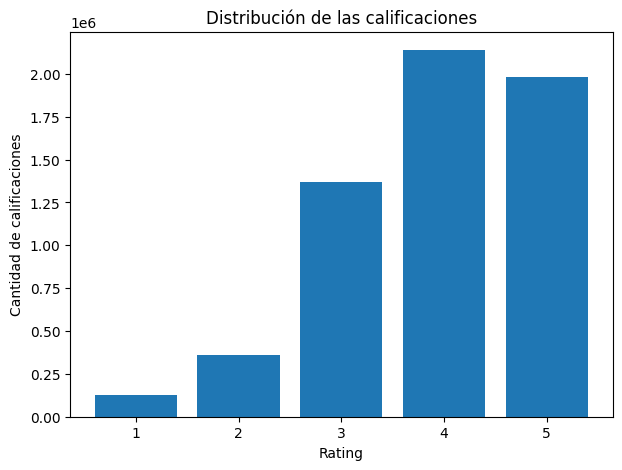

In [3]:
usuarios = ratings["user_id"].nunique()
libros = ratings["book_id"].nunique()
calificaciones = len(ratings)

print(f"Cantidad de usuarios: {usuarios}")
print(f"Cantidad de libros calificados: {libros}")
print(f"Cantidad total de calificaciones: {calificaciones}")

distribucion_ratings = (
    ratings["rating"]
    .value_counts()
    .sort_index()
    .reset_index()
)

distribucion_ratings.columns = ["Rating", "Cantidad"]

plt.figure(figsize=(7,5))

plt.bar(
    distribucion_ratings["Rating"],
    distribucion_ratings["Cantidad"]
)

plt.title("Distribución de las calificaciones")
plt.xlabel("Rating")
plt.ylabel("Cantidad de calificaciones")

plt.show()

Los resultados muestran una base amplia, con 53,424 usuarios, 10,000 libros y casi 6 millones de calificaciones. La mayoría de los ratings se concentra en valores de 4 y 5, mientras que las calificaciones bajas son poco frecuentes, lo que refleja una tendencia general hacia evaluaciones positivas. Este comportamiento deberá considerarse posteriormente al centrar las calificaciones por usuario.

Una vez comprendida la estructura general de las bases y el comportamiento de las calificaciones, el siguiente paso será preparar los datos para el sistema de recomendación mediante la construcción de la matriz usuario–libro y el preprocesamiento de las calificaciones.

## Paso 3. Preprocesamiento de los datos

Antes de aplicar los métodos de reducción de dimensionalidad y matrix completion, es necesario preparar los datos en una estructura adecuada. En este paso se construirá la matriz usuario–libro, se identificarán los valores faltantes y se separará una parte de las calificaciones conocidas para utilizarla posteriormente como conjunto de prueba. Además, las calificaciones se centrarán respecto a la media de cada usuario con el fin de reducir las diferencias en la forma en que cada persona utiliza la escala de evaluación.

Este preprocesamiento permitirá trabajar con una representación más adecuada de las preferencias de los usuarios y preparar la información para aplicar posteriormente PCA y los métodos de reconstrucción de la matriz.

### 3.1 Construcción de la matriz usuario–libro
Para construir el sistema de recomendación, primero se organizarán las calificaciones en una matriz usuario–libro. En esta matriz, cada fila representa a un usuario, cada columna representa a un libro y cada celda contiene la calificación asignada.

Cuando un usuario no haya calificado un libro, la celda correspondiente aparecerá como un valor faltante (NaN). Esta estructura será la base para los pasos posteriores de reducción de dimensionalidad y completado matricial. El taller indica precisamente trabajar con una matriz usuario–ítem con usuarios en filas, libros en columnas, ratings como valores y NaN en los huecos.

In [5]:
# Seleccionar los usuarios más activos
n_usuarios = 500
n_libros = 500

usuarios_activos = (
    ratings["user_id"]
    .value_counts()
    .head(n_usuarios)
    .index
)

libros_populares = (
    ratings["book_id"]
    .value_counts()
    .head(n_libros)
    .index
)

# Crear subconjunto
ratings_sub = ratings[
    ratings["user_id"].isin(usuarios_activos) &
    ratings["book_id"].isin(libros_populares)
].copy()

print("Usuarios:", ratings_sub["user_id"].nunique())
print("Libros:", ratings_sub["book_id"].nunique())
print("Ratings:", len(ratings_sub))

Usuarios: 500
Libros: 500
Ratings: 45371


In [6]:
matriz_usuario_libro = ratings_sub.pivot_table(
    index="user_id",
    columns="book_id",
    values="rating"
)

print("Dimensiones de la matriz:", matriz_usuario_libro.shape)

matriz_usuario_libro.head()

Dimensiones de la matriz: (500, 500)


book_id,1,2,3,4,5,6,7,8,9,10,...,682,693,696,704,714,715,730,733,773,826
user_id,,,,,,,,,,,,,,,,,,,,,
314,5.0,NaN,3.0,NaN,4.0,5.0,NaN,NaN,NaN,NaN,...,NaN,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
368,4.0,NaN,2.0,NaN,NaN,NaN,NaN,NaN,2.0,NaN,...,NaN,NaN,NaN,3.0,NaN,NaN,4.0,3.0,NaN,NaN
439,3.0,NaN,NaN,5.0,4.0,NaN,3.0,NaN,3.0,4.0,...,NaN,2.0,NaN,3.0,NaN,NaN,NaN,2.0,NaN,NaN
588,5.0,NaN,1.0,NaN,NaN,NaN,NaN,3.0,3.0,NaN,...,NaN,NaN,NaN,NaN,NaN,3.0,NaN,NaN,NaN,NaN
725,5.0,NaN,NaN,NaN,NaN,5.0,NaN,NaN,NaN,NaN,...,NaN,3.0,NaN,5.0,NaN,NaN,4.0,NaN,NaN,NaN


### 3.2 Visualización de valores faltantes
A continuación, se visualizará una parte de la matriz para observar la distribución de las calificaciones conocidas y los valores faltantes.

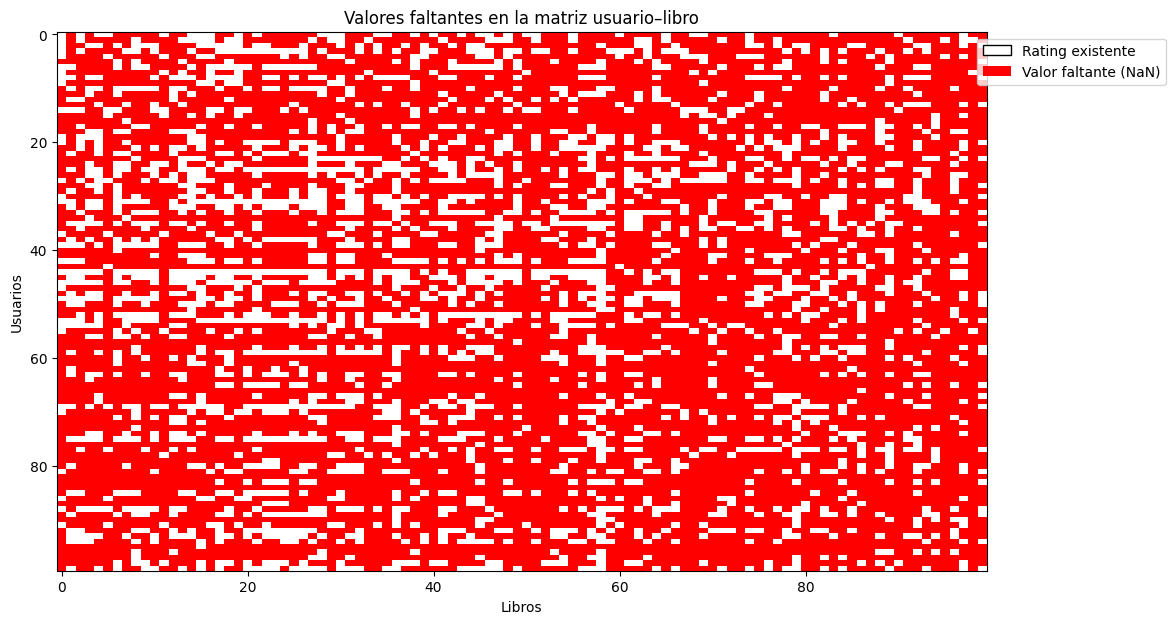

In [7]:
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

plt.figure(figsize=(12, 7))

mapa_faltantes = matriz_usuario_libro.iloc[:100, :100].isna()

cmap = ListedColormap(["white", "red"])

plt.imshow(
    mapa_faltantes,
    aspect="auto",
    cmap=cmap
)

plt.title("Valores faltantes en la matriz usuario–libro")
plt.xlabel("Libros")
plt.ylabel("Usuarios")

leyenda = [
    Patch(facecolor="white", edgecolor="black", label="Rating existente"),
    Patch(facecolor="red", label="Valor faltante (NaN)")
]

plt.legend(
    handles=leyenda,
    loc="upper right",
    bbox_to_anchor=(1.20, 1)
)

plt.show()

Las celdas blancas representan calificaciones conocidas, mientras que las celdas rojas corresponden a valores faltantes. La presencia de una gran cantidad de NaN es esperada en un sistema de recomendación, ya que cada usuario solamente ha calificado una pequeña parte de los libros disponibles.

### 3.3 División en entrenamiento y prueba
Para evaluar posteriormente la capacidad de reconstrucción del sistema, se ocultará aproximadamente el 10% de las calificaciones conocidas de cada usuario.

Las calificaciones restantes formarán el conjunto de entrenamiento, mientras que las ocultadas se conservarán como conjunto de prueba. Esto sigue la metodología indicada en el taller, donde se propone esconder aleatoriamente una parte de los ratings para evaluación.

In [8]:
matriz_original = matriz_usuario_libro.copy()
matriz_train = matriz_original.copy()

filas_test = []
columnas_test = []
ratings_test = []

rng = np.random.default_rng(27)

for i in range(len(matriz_original)):

    columnas_con_rating = np.where(
        ~matriz_original.iloc[i].isna()
    )[0]

    if len(columnas_con_rating) >= 2:

        n_test = max(
            1,
            int(len(columnas_con_rating) * 0.10)
        )

        n_test = min(
            n_test,
            len(columnas_con_rating) - 1
        )

        columnas_ocultas = rng.choice(
            columnas_con_rating,
            size=n_test,
            replace=False
        )

        for j in columnas_ocultas:

            filas_test.append(i)
            columnas_test.append(j)

            ratings_test.append(
                matriz_original.iloc[i, j]
            )

            matriz_train.iloc[i, j] = np.nan

filas_test = np.array(filas_test)
columnas_test = np.array(columnas_test)
ratings_test = np.array(ratings_test)

print("Ratings de prueba:", len(ratings_test))

Ratings de prueba: 4299


### 3.4 Centrado de las calificaciones por usuario
No todos los usuarios utilizan la escala de calificación de la misma manera. Algunos pueden otorgar calificaciones altas con mayor frecuencia, mientras que otros pueden ser más estrictos.

Para reducir estas diferencias, se calculará el promedio de las calificaciones de entrenamiento de cada usuario y se restará de sus ratings. De esta forma, las calificaciones quedarán centradas alrededor de cero.

In [9]:
# Media de cada usuario
media_usuario = matriz_train.mean(axis=1)

# Media global como respaldo
media_global = np.nanmean(matriz_train.to_numpy())

media_usuario = media_usuario.fillna(media_global)

# Centrar ratings
matriz_centrada = matriz_train.sub(
    media_usuario,
    axis=0
)

matriz_centrada.head()

book_id,1,2,3,4,5,6,7,8,9,10,...,682,693,696,704,714,715,730,733,773,826
user_id,,,,,,,,,,,,,,,,,,,,,
314,NaN,NaN,-0.626506,NaN,0.373494,1.373494,NaN,NaN,NaN,NaN,...,NaN,-0.626506,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
368,0.973684,NaN,-1.026316,NaN,NaN,NaN,NaN,NaN,-1.026316,NaN,...,NaN,NaN,NaN,-0.026316,NaN,NaN,0.973684,-0.026316,NaN,NaN
439,-0.471910,NaN,NaN,1.52809,0.528090,NaN,-0.47191,NaN,-0.471910,0.52809,...,NaN,-1.471910,NaN,-0.471910,NaN,NaN,NaN,-1.471910,NaN,NaN
588,1.383838,NaN,-2.616162,NaN,NaN,NaN,NaN,-0.616162,-0.616162,NaN,...,NaN,NaN,NaN,NaN,NaN,-0.616162,NaN,NaN,NaN,NaN
725,0.877778,NaN,NaN,NaN,NaN,0.877778,NaN,NaN,NaN,NaN,...,NaN,-1.122222,NaN,0.877778,NaN,NaN,-0.122222,NaN,NaN,NaN


In [10]:
medias_centradas = matriz_centrada.mean(axis=1)

print(
    "Promedio de las medias centradas:",
    medias_centradas.mean()
)

Promedio de las medias centradas: -1.7402667688100373e-18


## Paso 4. Aplicación de PCA

### 4.1 Imputación temporal
PCA no puede trabajar directamente con valores faltantes, por lo que es necesario realizar una imputación temporal antes de aplicarlo.

Como las calificaciones ya fueron centradas alrededor de la media de cada usuario, los valores faltantes se rellenarán temporalmente con cero. En este contexto, cero representa aproximadamente una calificación promedio para cada usuario.

In [11]:
matriz_pca_inicial = matriz_centrada.fillna(0)

matriz_pca_inicial.head()

book_id,1,2,3,4,5,6,7,8,9,10,...,682,693,696,704,714,715,730,733,773,826
user_id,,,,,,,,,,,,,,,,,,,,,
314,0.000000,0.0,-0.626506,0.00000,0.373494,1.373494,0.00000,0.000000,0.000000,0.00000,...,0.0,-0.626506,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0
368,0.973684,0.0,-1.026316,0.00000,0.000000,0.000000,0.00000,0.000000,-1.026316,0.00000,...,0.0,0.000000,0.0,-0.026316,0.0,0.000000,0.973684,-0.026316,0.0,0.0
439,-0.471910,0.0,0.000000,1.52809,0.528090,0.000000,-0.47191,0.000000,-0.471910,0.52809,...,0.0,-1.471910,0.0,-0.471910,0.0,0.000000,0.000000,-1.471910,0.0,0.0
588,1.383838,0.0,-2.616162,0.00000,0.000000,0.000000,0.00000,-0.616162,-0.616162,0.00000,...,0.0,0.000000,0.0,0.000000,0.0,-0.616162,0.000000,0.000000,0.0,0.0
725,0.877778,0.0,0.000000,0.00000,0.000000,0.877778,0.00000,0.000000,0.000000,0.00000,...,0.0,-1.122222,0.0,0.877778,0.0,0.000000,-0.122222,0.000000,0.0,0.0


### 4.2 Aplicación de PCA
PCA transforma las variables originales en un nuevo conjunto de variables llamadas componentes principales. Estos componentes son combinaciones de las variables originales y están construidos de manera que el primero capture la mayor cantidad posible de variabilidad de los datos, el segundo capture la mayor parte de la variabilidad restante, y así sucesivamente. Además, los componentes obtenidos no están correlacionados entre sí.

En este sistema de recomendación, cada columna de la matriz representa un libro, por lo que inicialmente se trabaja con 500 variables. Al ejecutar PCA sin especificar un número de componentes, el algoritmo calcula todos los componentes posibles. Por esta razón, el resultado indica una cantidad máxima de 500 componentes principales.

Sin embargo, no necesariamente será necesario conservar los 500 componentes. En los siguientes pasos se analizará la varianza explicada por cada componente para determinar cuántos son suficientes para representar la mayor parte de la información contenida en la matriz original.

In [12]:
from sklearn.decomposition import PCA

pca = PCA()

datos_pca = pca.fit_transform(
    matriz_pca_inicial
)

print(
    "Cantidad máxima de componentes:",
    len(pca.explained_variance_ratio_)
)

Cantidad máxima de componentes: 500


### 4.3 Varianza explicada
Después de aplicar PCA, es necesario determinar cuánta información conserva cada componente principal. Para ello se utiliza la proporción de varianza explicada, que indica qué porcentaje de la variabilidad total de los datos representa cada componente.

Los primeros componentes concentran la mayor cantidad de información, mientras que los componentes posteriores aportan cada vez menos. La variable explained_variance_ratio_ contiene la proporción explicada por cada componente, mientras que np.cumsum() permite calcular la varianza explicada acumulada, es decir, cuánta información se conserva al utilizar varios componentes en conjunto.

La primera gráfica muestra la aportación individual de cada componente. Esta visualización permite identificar si existe un punto a partir del cual agregar más componentes aporta muy poca información adicional.

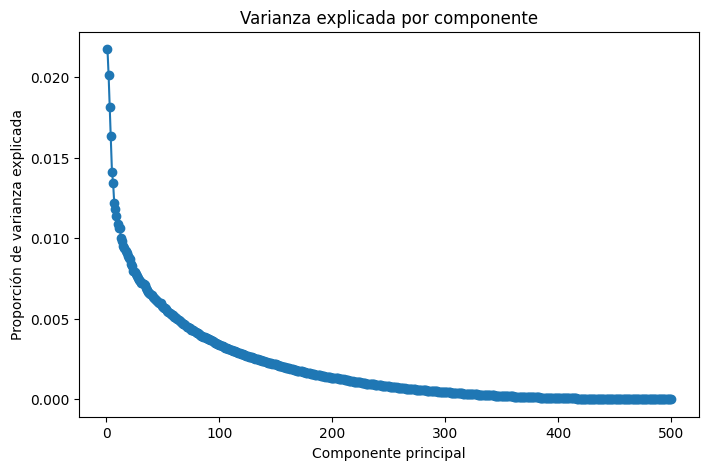

In [14]:
varianza_explicada = pca.explained_variance_ratio_

varianza_acumulada = np.cumsum(
    varianza_explicada
)

plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(varianza_explicada) + 1),
    varianza_explicada,
    marker="o"
)

plt.xlabel("Componente principal")
plt.ylabel("Proporción de varianza explicada")
plt.title("Varianza explicada por componente")

plt.show()

La varianza explicada acumulada representa la cantidad total de información que se conserva al utilizar los primeros componentes principales en conjunto. A diferencia de la varianza explicada individual, que muestra cuánto aporta cada componente por separado, la acumulada va sumando progresivamente la contribución de cada componente.

Por ejemplo, si los primeros 50 componentes alcanzan una varianza explicada acumulada de 0.80, significa que esos 50 componentes conservan aproximadamente el 80% de la variabilidad presente en los datos originales.

En este análisis se utiliza como referencia un umbral del 90%. El objetivo es encontrar la menor cantidad de componentes capaz de conservar al menos el 90% de la información de la matriz original. De esta manera, es posible reducir el número de dimensiones sin perder una cantidad considerable de información.

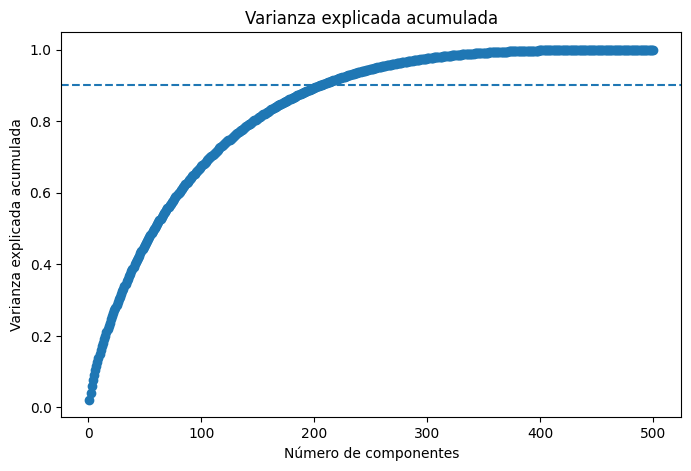

In [15]:
plt.figure(figsize=(8,5))

plt.plot(
    range(1, len(varianza_acumulada) + 1),
    varianza_acumulada,
    marker="o"
)

plt.axhline(
    y=0.90,
    linestyle="--"
)

plt.xlabel("Número de componentes")
plt.ylabel("Varianza explicada acumulada")
plt.title("Varianza explicada acumulada")

plt.show()

La curva muestra que aproximadamente 200 componentes son suficientes para conservar el 90% de la variabilidad de los datos. A partir de ese punto, agregar más componentes genera mejoras cada vez menores, por lo que se puede reducir la dimensionalidad de 500 variables a alrededor de 200 componentes sin perder una cantidad considerable de información.

### 4.4 Selección de número de componentes
La selección del número de componentes consiste en decidir cuántos componentes principales se van a conservar después de aplicar PCA. Aunque PCA puede generar tantos componentes como variables originales, no siempre es necesario utilizar todos, ya que los primeros componentes concentran la mayor parte de la variabilidad de los datos.

Para elegir cuántos conservar, se utiliza la varianza explicada acumulada. Esta indica qué proporción de la información total se mantiene al usar los primeros \(n\) componentes. En este caso, se estableció un umbral del 90%, por lo que se busca el menor número de componentes que permita conservar al menos ese porcentaje de la variabilidad original.

El código identifica automáticamente el primer punto en el que la varianza acumulada alcanza o supera 0.90:

In [16]:
n_componentes = np.argmax(
    varianza_acumulada >= 0.90
) + 1

print(
    "Componentes necesarios para explicar el 90%:",
    n_componentes
)

Componentes necesarios para explicar el 90%: 205


El resultado obtenido fue de 205 componentes principales. Esto significa que, de las 500 dimensiones originales de la matriz, solo es necesario conservar 205 componentes para representar al menos el 90% de la variabilidad presente en los datos.

En otras palabras, PCA permite reducir la dimensionalidad de 500 a 205 componentes, lo que representa una reducción aproximada del 59%, manteniendo la mayor parte de la información relevante.

El hecho de necesitar 205 componentes también indica que la información está distribuida entre una cantidad considerable de componentes, por lo que las preferencias de los usuarios presentan una estructura relativamente compleja y no pueden resumirse adecuadamente con solo unos pocos patrones.

### 4.5 Reconstrucción del PCA
Después de seleccionar los 205 componentes principales, el siguiente paso consiste en reconstruir una aproximación de la matriz original a partir de esa representación reducida.

La idea es que PCA primero transforma la matriz original de 500 variables a un espacio de menor dimensión, en este caso de 205 componentes. Posteriormente, mediante inverse_transform(), esos 205 componentes se vuelven a proyectar al espacio original de 500 variables.

Sin embargo, la matriz reconstruida no es idéntica a la original, ya que solamente se utilizó la información contenida en los componentes seleccionados. Por esta razón, la reconstrucción representa una aproximación de las calificaciones originales que conserva aproximadamente el 90% de la variabilidad de los datos.

In [17]:
pca_reducido = PCA(
    n_components=n_componentes
)

datos_reducidos = pca_reducido.fit_transform(
    matriz_pca_inicial
)

matriz_pca_reconstruida = (
    pca_reducido.inverse_transform(
        datos_reducidos
    )
)

Antes de aplicar PCA, las calificaciones fueron centradas restando la media individual de cada usuario. Por lo tanto, los valores reconstruidos siguen estando expresados respecto a esa media.

El código a continuación vuelve a sumar la media correspondiente a cada usuario para recuperar la escala original de las calificaciones.

In [18]:
matriz_pca_reconstruida = (
    matriz_pca_reconstruida
    + media_usuario.to_numpy()[:, np.newaxis]
)

matriz_pca_reconstruida = pd.DataFrame(
    matriz_pca_reconstruida,
    index=matriz_usuario_libro.index,
    columns=matriz_usuario_libro.columns
)

matriz_pca_reconstruida = (
    matriz_pca_reconstruida.clip(1, 5)
)

matriz_pca_reconstruida.head()

book_id,1,2,3,4,5,6,7,8,9,10,...,682,693,696,704,714,715,730,733,773,826
user_id,,,,,,,,,,,,,,,,,,,,,
314,3.539600,3.481665,2.967866,3.805995,3.992846,4.984384,3.600786,3.622616,3.599633,3.542960,...,3.545102,3.199875,3.595988,3.683409,3.674017,3.683488,3.634024,3.547261,3.650035,3.536371
368,4.057845,3.116504,2.135863,3.080481,3.040710,3.140783,3.105580,3.022838,1.972050,2.981696,...,3.192975,2.988373,2.949893,3.042579,2.908465,3.015307,4.018441,3.087430,3.187904,3.178010
439,3.154828,3.498965,3.450984,4.899886,4.107830,3.543268,3.076871,3.572962,3.017249,3.957860,...,3.582455,2.154382,3.380954,3.238610,3.484824,3.376652,3.347687,2.198076,3.438374,3.228679
588,4.796289,3.695010,1.000000,3.732444,3.576704,3.607680,3.741395,3.004825,3.032002,3.635378,...,3.673336,3.511906,3.551806,3.516593,3.599129,3.285253,3.757901,3.594801,3.617788,3.521043
725,5.000000,4.105943,4.138354,4.161534,4.163525,4.939768,4.226388,4.132645,4.097563,4.164804,...,3.991791,3.015169,3.961692,4.885021,4.153168,4.267695,3.839185,4.088935,4.107943,4.075730


La reconstrucción mediante PCA permite regresar de la representación reducida de 205 componentes al espacio original de 500 libros. Sin embargo, la matriz resultante es una aproximación de la original, ya que se descartó aproximadamente el 10% de la variabilidad al reducir la dimensionalidad.

Los valores obtenidos representan estimaciones de las calificaciones que cada usuario podría asignar a los diferentes libros. Posteriormente, estas estimaciones se compararán con las calificaciones reales que fueron ocultadas en el conjunto de prueba para determinar qué tan buena fue la reconstrucción realizada mediante PCA.

## Paso 5. Matrix Completion
SoftImpute realiza un proceso iterativo de completado matricial en el que busca reconstruir los valores faltantes utilizando una representación de bajo rango de la matriz usuario–libro. Durante cada iteración, el algoritmo actualiza las estimaciones y evalúa el error obtenido sobre las calificaciones conocidas.

In [21]:
from fancyimpute import SoftImpute

soft_impute = SoftImpute()

matriz_soft_centrada = soft_impute.fit_transform(
    matriz_centrada.to_numpy()
)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


[SoftImpute] Max Singular Value of X_init = 33.147369
[SoftImpute] Iter 1: observed MAE=0.047517 rank=449
[SoftImpute] Iter 2: observed MAE=0.047256 rank=423
[SoftImpute] Iter 3: observed MAE=0.046945 rank=404
[SoftImpute] Iter 4: observed MAE=0.046611 rank=387
[SoftImpute] Iter 5: observed MAE=0.046293 rank=373
[SoftImpute] Iter 6: observed MAE=0.045980 rank=359
[SoftImpute] Iter 7: observed MAE=0.045684 rank=350
[SoftImpute] Iter 8: observed MAE=0.045420 rank=341
[SoftImpute] Iter 9: observed MAE=0.045162 rank=332
[SoftImpute] Iter 10: observed MAE=0.044919 rank=324
[SoftImpute] Iter 11: observed MAE=0.044704 rank=318
[SoftImpute] Iter 12: observed MAE=0.044498 rank=312
[SoftImpute] Iter 13: observed MAE=0.044293 rank=306
[SoftImpute] Iter 14: observed MAE=0.044105 rank=301
[SoftImpute] Iter 15: observed MAE=0.043943 rank=295
[SoftImpute] Iter 16: observed MAE=0.043754 rank=289
[SoftImpute] Iter 17: observed MAE=0.043606 rank=287
[SoftImpute] Iter 18: observed MAE=0.043481 rank=282
[

En los resultados se observa que el MAE sobre los valores observados disminuye progresivamente hasta alcanzar aproximadamente 0.0403, lo cual indica que la reconstrucción interna mejora conforme avanzan las iteraciones. Al mismo tiempo, el rango de la matriz disminuye hasta aproximadamente 182, lo que muestra que SoftImpute está representando la información mediante una estructura más compacta.

El algoritmo se detuvo después de 100 iteraciones con un valor de regularización de aproximadamente 0.663. Como el error cambia muy poco en las últimas iteraciones, esto sugiere que el procedimiento se encontraba cercano a una solución estable. Sin embargo, este error interno no debe confundirse con el desempeño final del sistema, por lo que posteriormente se evalúan las predicciones sobre el conjunto de prueba utilizando MAE y RMSE.

La matriz reconstruida contiene una estimación de la calificación que cada usuario podría asignar a cada libro. Las filas representan usuarios y las columnas representan libros, mientras que cada celda contiene un rating estimado dentro de la escala de 1 a 5.

In [22]:
matriz_soft = (
    matriz_soft_centrada
    + media_usuario.to_numpy()[:, np.newaxis]
)

matriz_soft = pd.DataFrame(
    matriz_soft,
    index=matriz_usuario_libro.index,
    columns=matriz_usuario_libro.columns
)

matriz_soft = matriz_soft.clip(1, 5)

matriz_soft.head()

book_id,1,2,3,4,5,6,7,8,9,10,...,682,693,696,704,714,715,730,733,773,826
user_id,,,,,,,,,,,,,,,,,,,,,
314,4.235047,3.642038,3.000000,4.011337,4.000000,5.000000,3.874210,3.568069,3.304158,3.969791,...,3.375646,3.000000,3.606495,3.586205,3.872195,3.233635,3.660461,3.268035,3.477120,3.395468
368,4.000000,2.933013,2.000000,3.566870,3.046507,3.406763,3.435224,3.367094,2.000000,2.619798,...,3.050323,2.785910,2.534850,3.000000,2.855468,3.127589,4.000000,3.000000,3.444752,3.339078
439,3.000000,3.527035,2.555876,5.000000,4.000000,3.705423,3.000000,3.619581,3.000000,4.000000,...,3.416378,2.000000,3.332232,3.000000,3.836423,3.145972,3.376163,2.000000,3.236809,3.047093
588,5.000000,4.230966,1.000000,4.176419,3.598059,3.449027,4.103399,3.000000,3.000000,4.074126,...,3.357880,2.944459,3.508548,3.627455,3.733322,3.000000,3.978460,4.137969,3.188504,3.436498
725,5.000000,4.278684,3.056572,4.873433,4.517113,5.000000,3.917349,4.741362,3.580051,4.378895,...,3.646256,3.000000,3.823152,5.000000,4.254415,3.991507,4.000000,4.374135,3.751242,3.610353


A diferencia de la matriz original, donde existían numerosos valores faltantes debido a que los usuarios no habían calificado todos los libros, después del proceso de reconstrucción se obtienen valores estimados para esas posiciones. Por ejemplo, para el usuario 314, el sistema estima una calificación aproximada de 4.24 para el libro 1 y de 3.64 para el libro 2.

También se observa que algunos valores permanecen exactamente en números enteros como 3, 4 o 5. Esto puede ocurrir porque corresponden a calificaciones conocidas originalmente o porque la reconstrucción produjo valores muy cercanos a esos niveles. En cambio, valores decimales como 4.23 o 3.57 representan estimaciones generadas por el modelo.

Esta matriz será utilizada posteriormente para identificar, para cada usuario, cuáles libros no ha calificado y cuáles tienen las puntuaciones estimadas más altas, permitiendo así generar recomendaciones personalizadas.

## Paso 6. Evaluación de PCA y SoftImpute
Después de reconstruir la matriz usuario–libro con ambos métodos, es necesario evaluar qué tan precisas fueron sus estimaciones. Para hacerlo de manera justa, se utilizarán únicamente las posiciones que fueron ocultadas previamente durante la creación del conjunto de prueba.

Estas posiciones contienen calificaciones reales conocidas, pero fueron eliminadas temporalmente de la matriz de entrenamiento. De esta forma, los modelos intentaron reconstruirlas sin tener acceso a sus valores originales.

### 6.1 Obtener las predicciones
El siguiente código extrae las calificaciones estimadas por cada método exactamente en las posiciones correspondientes al conjunto de prueba.

In [23]:
predicciones_pca = matriz_pca_reconstruida.to_numpy()[
    filas_test,
    columnas_test
]

predicciones_soft = matriz_soft.to_numpy()[
    filas_test,
    columnas_test
]

### 6.2 Calcular MAE y RMSE
Para evaluar la calidad de las reconstrucciones se calcularon el MAE y el RMSE utilizando las calificaciones ocultadas en el conjunto de prueba. El MAE representa el error promedio de las predicciones en unidades de rating, mientras que el RMSE penaliza con mayor intensidad los errores grandes. En ambas métricas, valores menores indican una reconstrucción más precisa. Estas medidas permitirán comparar directamente el desempeño de PCA y SoftImpute.

In [24]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

# PCA
mae_pca = mean_absolute_error(
    ratings_test,
    predicciones_pca
)

rmse_pca = np.sqrt(
    mean_squared_error(
        ratings_test,
        predicciones_pca
    )
)

# SoftImpute
mae_soft = mean_absolute_error(
    ratings_test,
    predicciones_soft
)

rmse_soft = np.sqrt(
    mean_squared_error(
        ratings_test,
        predicciones_soft
    )
)

### 6.3 Tabla comparativa
Los valores de MAE y RMSE permiten comparar qué tan bien cada método reconstruye las calificaciones ocultadas. Valores menores indican una mayor precisión.

PCA realiza la reconstrucción a partir de una representación de menor dimensión, mientras que SoftImpute está diseñado específicamente para completar valores faltantes de manera iterativa. La comparación permite analizar cuál de los dos métodos representa mejor las preferencias de los usuarios.

In [25]:
comparacion_modelos = pd.DataFrame({
    "Método": [
        "PCA",
        "SoftImpute"
    ],
    "MAE": [
        mae_pca,
        mae_soft
    ],
    "RMSE": [
        rmse_pca,
        rmse_soft
    ]
})

comparacion_modelos

,Método,MAE,RMSE
0,PCA,0.717365,0.925254
1,SoftImpute,0.694124,0.908324


Los resultados muestran que ambos métodos presentan un desempeño similar en la reconstrucción de las calificaciones. Sin embargo, SoftImpute obtuvo los menores valores tanto de MAE (0.6941) como de RMSE (0.9083), en comparación con PCA, que presentó un MAE de 0.7174 y un RMSE de 0.9253. Esto indica que SoftImpute logró aproximar ligeramente mejor las calificaciones reales ocultadas.

En términos del MAE, las predicciones realizadas mediante SoftImpute presentan, en promedio, una diferencia de aproximadamente 0.69 estrellas respecto a la calificación real. La diferencia entre ambos métodos es relativamente pequeña, por lo que PCA también logró conservar información relevante de las preferencias de los usuarios. Sin embargo, debido al menor error observado, se utilizará la matriz reconstruida mediante SoftImpute para generar las recomendaciones finales.

## Paso 7. Generación de recomendaciones
Una vez seleccionado SoftImpute como método de reconstrucción, se utilizarán sus calificaciones estimadas para generar recomendaciones personalizadas. Para ello, se seleccionará un usuario, se identificarán los libros que ya ha calificado y posteriormente se buscarán aquellos que todavía no ha evaluado y que presentan las mayores calificaciones estimadas.

Además, se mostrarán primero algunos de los libros favoritos del usuario para tener una referencia de sus preferencias y posteriormente se compararán con las recomendaciones generadas.

### 7.1 Seleccionar un usuario
Para que el ejemplo sea interesante, podemos seleccionar automáticamente un usuario que tenga suficientes calificaciones:

In [26]:
# Contar ratings conocidos por usuario
cantidad_ratings_usuario = matriz_original.notna().sum(axis=1)

# Seleccionar el usuario con más calificaciones
usuario_elegido = cantidad_ratings_usuario.idxmax()

print("Usuario seleccionado:", usuario_elegido)
print(
    "Cantidad de libros calificados:",
    cantidad_ratings_usuario.loc[usuario_elegido]
)

Usuario seleccionado: 13879
Cantidad de libros calificados: 151


### 7.2 Mostrar los libros favoritos del usuario
Antes de generar las recomendaciones, se revisan los libros mejor calificados por el usuario. Esto permite obtener una referencia de sus preferencias y posteriormente analizar si las recomendaciones generadas presentan cierta relación con los libros que anteriormente valoró de manera positiva.

In [27]:
ratings_usuario = matriz_original.loc[usuario_elegido]

# Conservar únicamente libros que sí calificó
ratings_usuario = ratings_usuario.dropna()

# Ordenar de mayor a menor
favoritos = (
    ratings_usuario
    .sort_values(ascending=False)
    .head(10)
)

favoritos_df = favoritos.reset_index()

favoritos_df.columns = [
    "book_id",
    "rating"
]

favoritos_df = favoritos_df.merge(
    books[
        ["book_id", "title", "authors"]
    ],
    on="book_id",
    how="left"
)

favoritos_df[
    ["title", "authors", "rating"]
]

,title,authors,rating
0,The Hobbit,J.R.R. Tolkien,5.0
1,Pride and Prejudice,Jane Austen,5.0
2,Water for Elephants,Sara Gruen,5.0
3,The Lovely Bones,Alice Sebold,5.0
4,The Fellowship of the Ring (The Lord of the Ri...,J.R.R. Tolkien,5.0
5,"The Girl with the Dragon Tattoo (Millennium, #1)","Stieg Larsson, Reg Keeland",5.0
6,The Diary of a Young Girl,"Anne Frank, Eleanor Roosevelt, B.M. Mooyaart-D...",5.0
7,Jane Eyre,"Charlotte Brontë, Michael Mason",5.0
8,Bridge to Terabithia,Katherine Paterson,5.0
9,The Fountainhead,"Ayn Rand, Leonard Peikoff",5.0


### 7.3 Identificar libros no calificados
Ahora necesitamos evitar recomendarle algo que ya calificó:

In [28]:
# IDs de libros que el usuario ya calificó
libros_calificados = ratings_usuario.index

# Predicciones de SoftImpute para ese usuario
predicciones_usuario = matriz_soft.loc[
    usuario_elegido
]

# Quitar libros ya calificados
predicciones_no_vistos = (
    predicciones_usuario
    .drop(index=libros_calificados)
)

print(
    "Libros disponibles para recomendar:",
    len(predicciones_no_vistos)
)

Libros disponibles para recomendar: 349


### 7.4 Obtener las 10 mejores recomendaciones para el usuario

In [29]:
top_recomendaciones = (
    predicciones_no_vistos
    .sort_values(ascending=False)
    .head(10)
)

recomendaciones = (
    top_recomendaciones
    .reset_index()
)

recomendaciones.columns = [
    "book_id",
    "rating_estimado"
]

recomendaciones = recomendaciones.merge(
    books[
        ["book_id", "title", "authors"]
    ],
    on="book_id",
    how="left"
)

recomendaciones[
    [
        "title",
        "authors",
        "rating_estimado"
    ]
]

,title,authors,rating_estimado
0,Romeo and Juliet,"William Shakespeare, Robert Jackson",4.939168
1,The Great Gatsby,F. Scott Fitzgerald,4.537116
2,To Kill a Mockingbird,Harper Lee,4.506109
3,Wuthering Heights,"Emily Brontë, Richard J. Dunn",4.484613
4,Goodnight Moon,"Margaret Wise Brown, Clement Hurd",4.393895
5,Speak,Laurie Halse Anderson,4.382229
6,"Mockingjay (The Hunger Games, #3)",Suzanne Collins,4.375757
7,The Color Purple,Alice Walker,4.339321
8,"Little Women (Little Women, #1)",Louisa May Alcott,4.315677
9,All the Light We Cannot See,Anthony Doerr,4.285020


La tabla muestra los diez libros no calificados previamente por el usuario que recibieron las mayores puntuaciones estimadas por SoftImpute. Estos libros constituyen las recomendaciones personalizadas generadas por el sistema.

El rating estimado no corresponde a una calificación que el usuario haya realizado realmente, sino a la predicción generada a partir de los patrones encontrados en las calificaciones de los demás usuarios y en el comportamiento previo del usuario seleccionado.

## Paso 8. Análisis de las recomendaciones mediante tags
Para analizar con mayor detalle las recomendaciones generadas, se utilizarán las etiquetas asociadas a cada libro. Estas etiquetas permiten identificar temas, géneros o características frecuentes tanto en los libros favoritos del usuario como en los libros recomendados.

De esta manera, será posible comparar ambos grupos y observar si el sistema recomienda libros relacionados con los intereses previos del usuario.

### 8.1 Unir book_tags con tags
Primero relacionamos el identificador de cada etiqueta con su nombre:

In [30]:
tags_completos = book_tags.merge(
    tags,
    on="tag_id",
    how="left"
)

tags_completos.head()

,goodreads_book_id,tag_id,count,tag_name
0,1,30574,167697,to-read
1,1,11305,37174,fantasy
2,1,11557,34173,favorites
3,1,8717,12986,currently-reading
4,1,33114,12716,young-adult


### 8.2 Obtener los tags de los libros favoritos del usuario

Este análisis permite identificar las etiquetas más frecuentes entre los libros mejor calificados por el usuario. Los tags con valores más altos representan temas o características que aparecen con mayor frecuencia dentro de sus libros favoritos y, por lo tanto, pueden servir como una aproximación a sus intereses.

Esta información no participa directamente en el entrenamiento del sistema de recomendación, ya que las recomendaciones fueron generadas a partir de los patrones de calificaciones. Sin embargo, permite realizar un análisis posterior para determinar si los libros recomendados presentan características similares a aquellos que el usuario ha valorado positivamente.

In [36]:
# Relacionar book_id con goodreads_book_id
favoritos_con_id = favoritos_df.merge(
    books[["book_id", "goodreads_book_id"]],
    on="book_id",
    how="left"
)

# Obtener los goodreads_book_id de los libros favoritos
ids_favoritos = favoritos_con_id["goodreads_book_id"]

# Filtrar los tags correspondientes a esos libros
tags_favoritos = tags_completos[
    tags_completos["goodreads_book_id"].isin(ids_favoritos)
].copy()

# Obtener los 15 tags con mayor presencia
top_tags_favoritos = (
    tags_favoritos
    .groupby("tag_name")["count"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)

top_tags_favoritos

,tag_name,count
0,to-read,862231
1,fantasy,75750
2,favorites,73423
3,classics,71786
4,fiction,56677
5,currently-reading,37343
6,books-i-own,16928
7,classic,13862
8,mystery,11935
9,non-fiction,11237


### 8.3 Obtener los tags de los libros recomendados para el usuario
En este paso se identificarán las etiquetas más frecuentes dentro de los libros recomendados por el sistema. Esto permitirá comparar posteriormente los temas presentes en las recomendaciones con los temas encontrados en los libros favoritos del usuario.
Primero es necesario relacionar los identificadores book_id de las recomendaciones con goodreads_book_id, ya que la base de tags utiliza este último identificador.

In [37]:
# Relacionar book_id con goodreads_book_id
recomendaciones_con_id = recomendaciones.merge(
    books[["book_id", "goodreads_book_id"]],
    on="book_id",
    how="left"
)

# Obtener los goodreads_book_id de los libros recomendados
ids_recomendados = recomendaciones_con_id["goodreads_book_id"]

# Filtrar los tags correspondientes a los libros recomendados
tags_recomendados = tags_completos[
    tags_completos["goodreads_book_id"].isin(ids_recomendados)
].copy()

# Obtener los 15 tags con mayor presencia
top_tags_recomendados = (
    tags_recomendados
    .groupby("tag_name")["count"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
    .reset_index()
)

top_tags_recomendados

,tag_name,count
0,to-read,1337992
1,classics,128892
2,favorites,106437
3,currently-reading,97703
4,fiction,53267
5,young-adult,32762
6,classic,23738
7,historical-fiction,20082
8,books-i-own,18552
9,owned,16906


La tabla resultante muestra las etiquetas con mayor presencia entre los libros recomendados por el sistema. Estas etiquetas permiten identificar los temas, géneros o características que aparecen con mayor frecuencia dentro de las recomendaciones.

Posteriormente, estos resultados podrán compararse con las etiquetas obtenidas de los libros favoritos del usuario. Si existen etiquetas similares entre ambos grupos, esto podría indicar que el sistema está generando recomendaciones relacionadas con los intereses que el usuario ha mostrado previamente.

### 8.4 Comparar los temas más frecuentes
En este paso se compararán las etiquetas más frecuentes presentes en los libros favoritos del usuario con las etiquetas más frecuentes de los libros recomendados por el sistema.

El objetivo es analizar si existe una relación temática entre ambos grupos. Si los libros recomendados presentan tags similares a los libros que el usuario ya ha calificado positivamente, esto puede indicar que el sistema está generando recomendaciones coherentes con sus preferencias previas.

La primera gráfica muestra los tags con mayor presencia entre los libros favoritos:

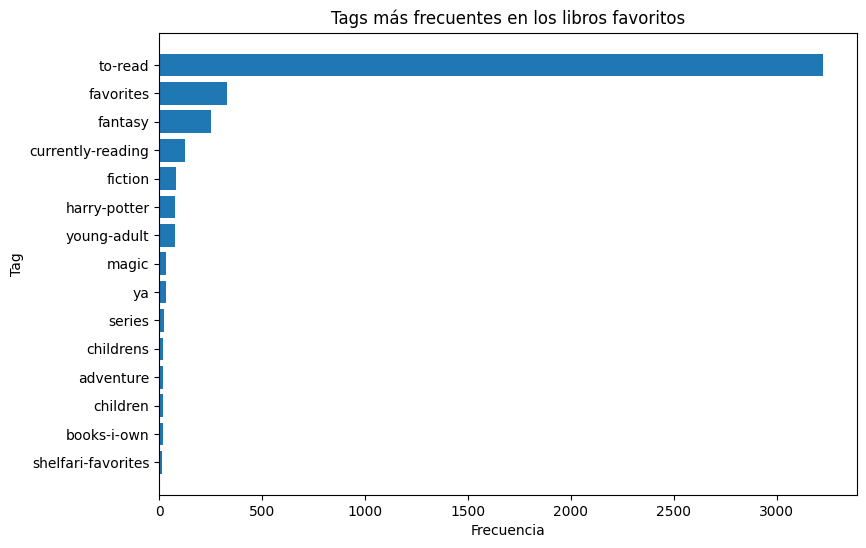

In [33]:
plt.figure(figsize=(9,6))

plt.barh(
    top_tags_favoritos["tag_name"],
    top_tags_favoritos["count"]
)

plt.xlabel("Frecuencia")
plt.ylabel("Tag")
plt.title("Tags más frecuentes en los libros favoritos")

plt.gca().invert_yaxis()

plt.show()

La segunda gráfica puede mostrar lo mismo para los libros recomendados:

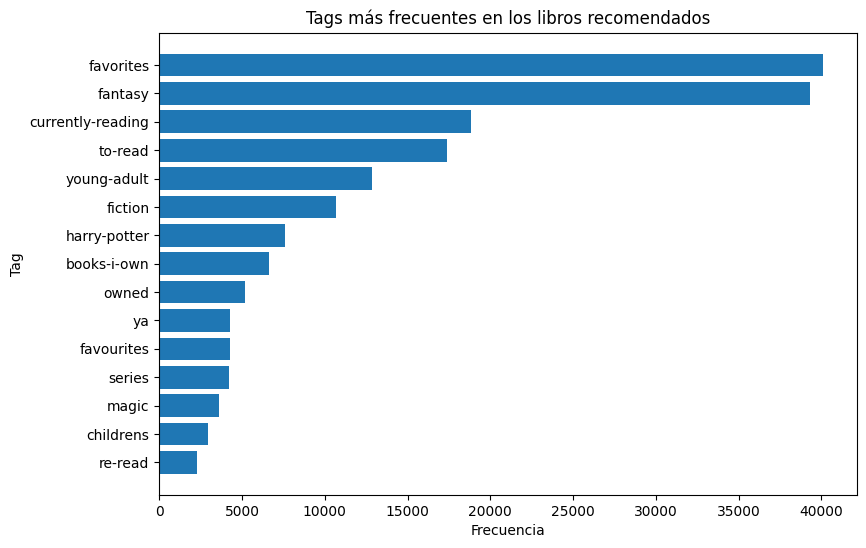

In [34]:
plt.figure(figsize=(9,6))

plt.barh(
    top_tags_recomendados["tag_name"],
    top_tags_recomendados["count"]
)

plt.xlabel("Frecuencia")
plt.ylabel("Tag")
plt.title("Tags más frecuentes en los libros recomendados")

plt.gca().invert_yaxis()

plt.show()

La comparación de ambas gráficas permite observar si los temas predominantes de los libros recomendados coinciden con aquellos presentes en los libros favoritos del usuario. La presencia de tags similares en ambos grupos sugeriría que las recomendaciones mantienen cierta relación con los intereses previamente mostrados por el usuario.

Sin embargo, esta comparación debe entenderse como una evaluación complementaria, ya que los tags no fueron utilizados directamente para generar las recomendaciones. El sistema fue construido a partir de los patrones de calificaciones, por lo que una coincidencia temática serviría como evidencia adicional de que las recomendaciones obtenidas son coherentes con las preferencias del usuario.

### 8.5 Identificar tags en común


In [38]:
tags_favoritos_set = set(
    top_tags_favoritos["tag_name"]
)

tags_recomendados_set = set(
    top_tags_recomendados["tag_name"]
)

tags_comunes = (
    tags_favoritos_set &
    tags_recomendados_set
)

print("Tags en común:")
print(tags_comunes)

Tags en común:
{'favorites', 'classic', 'owned', 'books-i-own', 'to-read', 'fiction', 'young-adult', 'classics', 'romance', 'currently-reading'}


La comparación de etiquetas permite observar si los libros recomendados comparten temas o características con los libros que el usuario ha calificado positivamente. La presencia de tags similares entre ambos grupos sugiere que las recomendaciones mantienen cierta relación con los intereses previos del usuario.

Sin embargo, esta comparación debe interpretarse como un análisis complementario, ya que el sistema de recomendación fue construido principalmente a partir de patrones de calificaciones y no directamente a partir de los tags. Por lo tanto, las coincidencias temáticas sirven como una forma adicional de evaluar la coherencia de las recomendaciones.

## Conclusiones
En este tutorial se desarrolló un sistema de recomendación de libros utilizando la base de datos Goodbooks-10k. El proceso comenzó con la exploración de las bases de datos y la construcción de una matriz usuario–libro, donde las calificaciones conocidas representaron las interacciones entre usuarios y libros, mientras que los valores faltantes correspondieron a libros que no habían sido calificados.

Posteriormente, se realizó el preprocesamiento de los datos mediante la separación de calificaciones en entrenamiento y prueba y el centrado de los ratings respecto a la media de cada usuario. Después se aplicaron dos estrategias de reconstrucción: PCA y SoftImpute.

PCA permitió reducir la dimensionalidad de la matriz y reconstruirla utilizando una cantidad menor de componentes principales, conservando gran parte de la variabilidad de los datos. Por otro lado, SoftImpute realizó un proceso iterativo de completado matricial enfocado directamente en estimar los valores faltantes.

Al comparar ambos métodos, SoftImpute presentó un MAE de 0.6941 y un RMSE de 0.9083, mientras que PCA obtuvo un MAE de 0.7174 y un RMSE de 0.9253. Aunque las diferencias fueron pequeñas, SoftImpute presentó un menor error en ambas métricas, por lo que se utilizó como método final para generar las recomendaciones.

A partir de la matriz reconstruida fue posible identificar libros que cada usuario no había calificado previamente y ordenarlos de acuerdo con su puntuación estimada. Esto permitió generar recomendaciones personalizadas basadas en los patrones de calificación presentes en los datos.
Finalmente, el análisis de etiquetas permitió comparar las características de los libros favoritos del usuario con las recomendaciones generadas. Esta comparación proporciona una forma adicional de analizar la coherencia de las recomendaciones, aunque debe considerarse que los tags no fueron utilizados directamente para entrenar el sistema, sino únicamente como herramienta de interpretación.

En general, los resultados muestran cómo las técnicas de reducción de dimensionalidad y completado matricial pueden utilizarse para identificar patrones en matrices con una gran cantidad de datos faltantes y generar recomendaciones personalizadas. Sin embargo, el desempeño del sistema depende de la cantidad y calidad de las calificaciones disponibles, por lo que usuarios con pocas interacciones pueden recibir recomendaciones menos representativas de sus preferencias.

Este ejercicio permitió observar que un sistema de recomendación no necesita conocer directamente los gustos de un usuario en todos los productos disponibles. A partir de un conjunto limitado de interacciones y de los patrones compartidos entre usuarios, es posible estimar preferencias desconocidas y generar recomendaciones. Al mismo tiempo, la comparación entre PCA y SoftImpute mostró que diferentes métodos de reconstrucción pueden producir resultados similares, aunque técnicas diseñadas específicamente para trabajar con valores faltantes pueden ofrecer una mejora en la precisión de las estimaciones.

## Bibliografía
Zając, Z. (2017). Goodbooks-10k: A new dataset for book recommendations. FastML. https://github.com/zygmuntz/goodbooks-10k